### CNN Project
### Accident Detection From CCTV Footage

c)	Use the following Accident detection Dataset link and create an end-to-end project to predict Accident has happened or not.

https://www.kaggle.com/datasets/ckay16/accident-detection-from-cctv-footage/data

i.	Import the dataset and perform the EDA and do the visualizations.
ii.	Create model from scratch using your own number of filters, loss functions, no. of epochs and check the accuracy.
iii.	Now use the pretrained model to check if accuracy gets improved.
iv.	After that, go for data augmentation and further check if accuracy has improved.
v.	Compare the training and testing accuracy with all these 3 approaches and suggest the best model.


### Solution

Downloading Dataset

In [92]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/

cp: cannot stat 'kaggle.json': No such file or directory


In [93]:
!kaggle datasets download -d ckay16/accident-detection-from-cctv-footage

Dataset URL: https://www.kaggle.com/datasets/ckay16/accident-detection-from-cctv-footage
License(s): ODbL-1.0
accident-detection-from-cctv-footage.zip: Skipping, found more recently modified local copy (use --force to force download)


In [94]:
import zipfile
zip_ref = zipfile.ZipFile('/content/accident-detection-from-cctv-footage.zip', 'r')
zip_ref.extractall('/content')
zip_ref.close()

Importing Libraries

In [95]:
import tensorflow as tf
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense,Conv2D,MaxPooling2D,Flatten,BatchNormalization,Dropout

Loading Dataset

In [96]:
# generators
train_ds = keras.utils.image_dataset_from_directory(
    directory = '/content/data/train',
    labels='inferred',
    label_mode = 'int',
    batch_size=32,
    image_size=(256,256)
)

test_ds = keras.utils.image_dataset_from_directory(
    directory = '/content/data/test',
    labels='inferred',
    label_mode = 'int',
    batch_size=32,
    image_size=(256,256),
    shuffle=False
)

val_ds = keras.utils.image_dataset_from_directory(
    directory = '/content/data/val',
    labels='inferred',
    label_mode = 'int',
    batch_size=32,
    image_size=(256,256)
)

Found 791 files belonging to 2 classes.
Found 100 files belonging to 2 classes.
Found 98 files belonging to 2 classes.


EDA & Visualizations

In [97]:
print(train_ds.class_names)

['Accident', 'Non Accident']


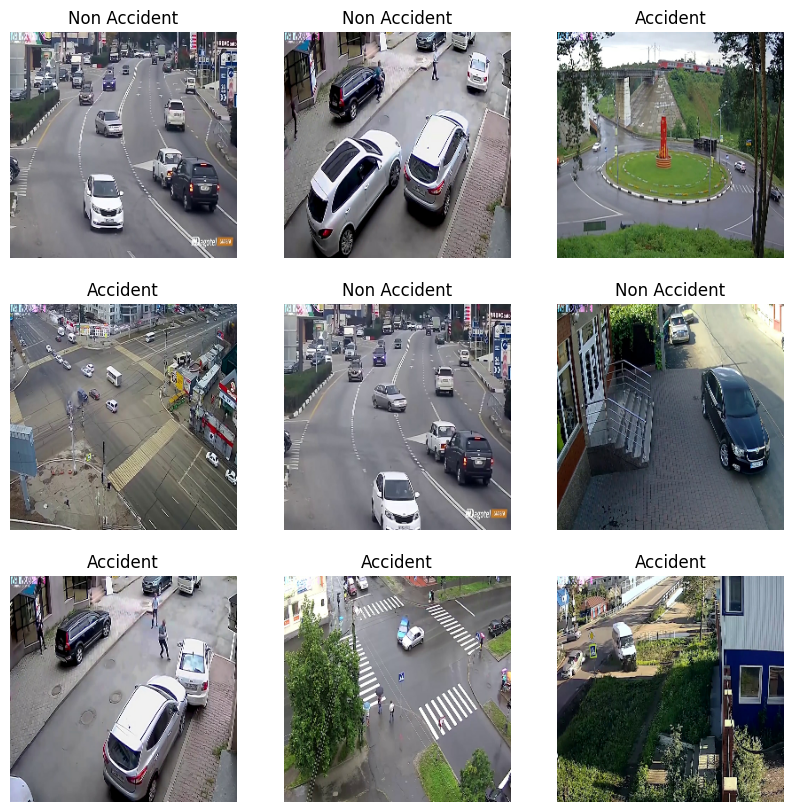

In [98]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10,10))

for images, labels in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3,3,i+1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(train_ds.class_names[int(labels[i])])
        plt.axis("off")

plt.show()

Normalize Data

In [99]:
# Normalize
def process(image,label):
    image = tf.cast(image/255. ,tf.float32)
    return image,label

train_ds = train_ds.map(process)
val_ds = val_ds.map(process)
test_ds = test_ds.map(process)

Creating CNN Model From Scratch

In [100]:
# create CNN model

model1 = Sequential()

model1.add(Conv2D(32,kernel_size=(3,3),padding='valid',activation='relu',input_shape=(256,256,3)))
model1.add(MaxPooling2D(pool_size=(2,2),strides=2,padding='valid'))

model1.add(Conv2D(64,kernel_size=(3,3),padding='valid',activation='relu'))
model1.add(MaxPooling2D(pool_size=(2,2),strides=2,padding='valid'))

model1.add(Conv2D(128,kernel_size=(3,3),padding='valid',activation='relu'))
model1.add(MaxPooling2D(pool_size=(2,2),strides=2,padding='valid'))

model1.add(Flatten())

model1.add(Dense(128,activation='relu'))
model1.add(Dense(64,activation='relu'))
model1.add(Dense(1,activation='sigmoid'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [101]:
model1.summary()

Model: "sequential_15"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_15 (Conv2D)              │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 125, 125, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 60, 60, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 30, 30, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_9 (Flatten)             │ (None, 115200)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 128)            │    14,745,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_27 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_28 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,847,297 (56.64 MB)

 Trainable params: 14,847,297 (56.64 MB)

 Non-trainable params: 0 (0.00 B)

In [102]:
model1.compile(
optimizer='adam',
loss='binary_crossentropy',
metrics=['accuracy']
)

In [103]:
history = model1.fit(train_ds,epochs=10,validation_data=val_ds)

Epoch 1/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 11s 235ms/step - accuracy: 0.4893 - loss: 0.8828 - val_accuracy: 0.4694 - val_loss: 0.6925
Epoch 2/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 6s 240ms/step - accuracy: 0.5714 - loss: 0.6769 - val_accuracy: 0.5714 - val_loss: 0.6379
Epoch 3/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 4s 168ms/step - accuracy: 0.6700 - loss: 0.6240 - val_accuracy: 0.6939 - val_loss: 0.5525
Epoch 4/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 5s 172ms/step - accuracy: 0.7016 - loss: 0.5873 - val_accuracy: 0.7857 - val_loss: 0.4866
Epoch 5/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 6s 238ms/step - accuracy: 0.7459 - loss: 0.5012 - val_accuracy: 0.6531 - val_loss: 0.5545
Epoch 6/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 4s 173ms/step - accuracy: 0.7800 - loss: 0.4710 - val_accuracy: 0.7959 - val_loss: 0.3836
Epoch 7/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 7s 246ms/step - accuracy: 0.8394 - loss: 0.3526 - val_accuracy: 0.8673 - val_loss: 0.3103
Epoch 8/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 8s 170ms/step - accuracy: 0.8761 - loss: 0.2960 - val_accuracy: 0

In [104]:
loss1, acc1 = model1.evaluate(test_ds)

print("CNN Accuracy:", acc1)

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 215ms/step - accuracy: 0.9300 - loss: 0.1882
CNN Accuracy: 0.9300000071525574


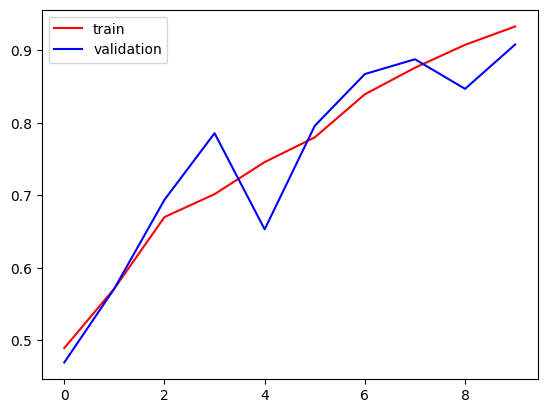

In [105]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'],color='red',label='train')
plt.plot(history.history['val_accuracy'],color='blue',label='validation')
plt.legend()
plt.show()

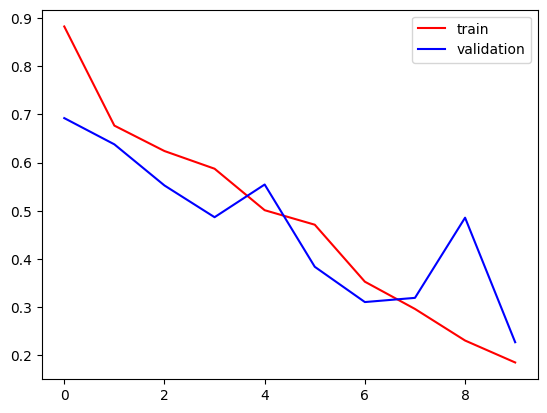

In [106]:
plt.plot(history.history['loss'],color='red',label='train')
plt.plot(history.history['val_loss'],color='blue',label='validation')
plt.legend()
plt.show()

### Using RSNet50 Pretrained Model

In [107]:
from tensorflow.keras.applications import VGG16
from tensorflow.keras.models import Sequential
from tensorflow.keras import layers



In [108]:
base_model = VGG16(
    weights='imagenet',
    include_top=False,
    input_shape=(256,256,3)
)

base_model.trainable = False

In [109]:
model2 = Sequential([
    base_model,

    layers.Flatten(),

    layers.Dense(128, activation='relu'),

    layers.Dropout(0.3),

    layers.Dense(1, activation='sigmoid')
])

In [110]:
model2.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [111]:
history2 = model2.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 19s 623ms/step - accuracy: 0.6498 - loss: 1.1480 - val_accuracy: 0.7143 - val_loss: 0.5180
Epoch 2/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 10s 386ms/step - accuracy: 0.7762 - loss: 0.4581 - val_accuracy: 0.8061 - val_loss: 0.4115
Epoch 3/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 10s 387ms/step - accuracy: 0.8496 - loss: 0.3565 - val_accuracy: 0.8980 - val_loss: 0.2527
Epoch 4/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 10s 383ms/step - accuracy: 0.8925 - loss: 0.2732 - val_accuracy: 0.9184 - val_loss: 0.2033
Epoch 5/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 10s 387ms/step - accuracy: 0.8597 - loss: 0.2849 - val_accuracy: 0.8163 - val_loss: 0.3363
Epoch 6/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 10s 382ms/step - accuracy: 0.8850 - loss: 0.2741 - val_accuracy: 0.8673 - val_loss: 0.2619
Epoch 7/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 10s 382ms/step - accuracy: 0.9064 - loss: 0.2286 - val_accuracy: 0.9286 - val_loss: 0.1990
Epoch 8/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 10s 382ms/step - accuracy: 0.9381 - loss: 0.1810 - val_accu

In [112]:
loss2, acc2 = model2.evaluate(test_ds)

print("VGG16 Accuracy:", acc2)

4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 503ms/step - accuracy: 0.9400 - loss: 0.1740
VGG16 Accuracy: 0.9399999976158142


### VGG16 + Data Augmentation

Data Augmentation

In [113]:
data_augmentation = Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
])

In [114]:
base_model_aug = VGG16(
    weights='imagenet',
    include_top=False,
    input_shape=(256,256,3)
)

base_model_aug.trainable = False

In [115]:
model3 = Sequential([
    data_augmentation,

    base_model_aug,

    layers.Flatten(),

    layers.Dense(128, activation='relu'),

    layers.Dropout(0.3),

    layers.Dense(1, activation='sigmoid')
])

In [116]:
model3.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [117]:
history3 = model3.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 7s 211ms/step - accuracy: 0.5904 - loss: 1.0097 - val_accuracy: 0.7653 - val_loss: 0.5845
Epoch 2/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 6s 243ms/step - accuracy: 0.6738 - loss: 0.6084 - val_accuracy: 0.7143 - val_loss: 0.5350
Epoch 3/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 5s 200ms/step - accuracy: 0.7080 - loss: 0.5505 - val_accuracy: 0.7449 - val_loss: 0.4767
Epoch 4/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 5s 203ms/step - accuracy: 0.6941 - loss: 0.5688 - val_accuracy: 0.7755 - val_loss: 0.5171
Epoch 5/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 10s 199ms/step - accuracy: 0.6915 - loss: 0.5531 - val_accuracy: 0.7653 - val_loss: 0.5034
Epoch 6/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 6s 248ms/step - accuracy: 0.7004 - loss: 0.5457 - val_accuracy: 0.7449 - val_loss: 0.5144
Epoch 7/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 5s 201ms/step - accuracy: 0.7219 - loss: 0.5278 - val_accuracy: 0.8265 - val_loss: 0.4315
Epoch 8/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 6s 229ms/step - accuracy: 0.7522 - loss: 0.4883 - val_accuracy: 0

In [118]:
loss3, acc3 = model3.evaluate(test_ds)

print("VGG16 + Augmentation Accuracy:", acc3)

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 208ms/step - accuracy: 0.7800 - loss: 0.4474
VGG16 + Augmentation Accuracy: 0.7799999713897705


### CNN from Scratch + Data Augmentation

In [119]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import *

# Data Augmentation
data_augmentation = Sequential([
    RandomFlip("horizontal"),
    RandomRotation(0.1),
    RandomZoom(0.1),
    RandomContrast(0.1)
])

# Model 4
model4 = Sequential()

# Data Augmentation
model4.add(data_augmentation)

# Conv Block 1
model4.add(Conv2D(
    32,
    kernel_size=(3,3),
    padding='valid',
    activation='relu',
    input_shape=(256,256,3)
))
model4.add(BatchNormalization())
model4.add(MaxPooling2D(pool_size=(2,2), strides=2))

# Conv Block 2
model4.add(Conv2D(
    64,
    kernel_size=(3,3),
    padding='valid',
    activation='relu'
))
model4.add(BatchNormalization())
model4.add(MaxPooling2D(pool_size=(2,2), strides=2))

# Conv Block 3
model4.add(Conv2D(
    128,
    kernel_size=(3,3),
    padding='valid',
    activation='relu'
))
model4.add(BatchNormalization())
model4.add(MaxPooling2D(pool_size=(2,2), strides=2))

# Dense Layers
model4.add(Flatten())

model4.add(Dense(128, activation='relu'))
model4.add(Dropout(0.3))

model4.add(Dense(64, activation='relu'))
model4.add(Dropout(0.3))

model4.add(Dense(1, activation='sigmoid'))


In [120]:
model4.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [121]:
history4 = model4.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 10s 193ms/step - accuracy: 0.5145 - loss: 9.2629 - val_accuracy: 0.4694 - val_loss: 3.8196
Epoch 2/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 6s 246ms/step - accuracy: 0.5424 - loss: 7.6565 - val_accuracy: 0.5510 - val_loss: 6.0283
Epoch 3/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 9s 184ms/step - accuracy: 0.5221 - loss: 4.8411 - val_accuracy: 0.5000 - val_loss: 2.5852
Epoch 4/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 6s 236ms/step - accuracy: 0.5322 - loss: 4.1199 - val_accuracy: 0.5408 - val_loss: 5.2080
Epoch 5/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 5s 189ms/step - accuracy: 0.5171 - loss: 2.3516 - val_accuracy: 0.5306 - val_loss: 3.7477
Epoch 6/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 6s 242ms/step - accuracy: 0.5676 - loss: 1.7981 - val_accuracy: 0.5306 - val_loss: 4.0140
Epoch 7/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 5s 183ms/step - accuracy: 0.5234 - loss: 1.1550 - val_accuracy: 0.5408 - val_loss: 2.7693
Epoch 8/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 5s 185ms/step - accuracy: 0.5563 - loss: 0.8597 - val_accuracy: 0

In [122]:
loss4, acc4 = model4.evaluate(test_ds)

print("CNN + Data Augmentation Accuracy:", acc4)

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 102ms/step - accuracy: 0.5300 - loss: 12.6014
CNN + Data Augmentation Accuracy: 0.5299999713897705


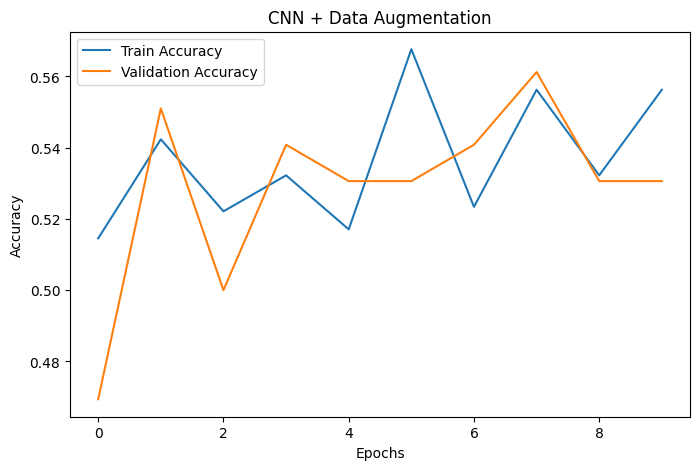

In [123]:
plt.figure(figsize=(8,5))

plt.plot(
    history4.history['accuracy'],
    label='Train Accuracy'
)

plt.plot(
    history4.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title("CNN + Data Augmentation")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

plt.show()

### Compare Models

In [124]:
results = pd.DataFrame({
    "Model":[
        "CNN Scratch",
        "CNN + Augmentation",
        "VGG16",
        "VGG16 + Augmentation"
    ],
    "Test Accuracy":[
        acc1,
        acc4,
        acc2,
        acc3
    ]
})

print(results)

                  Model  Test Accuracy
0           CNN Scratch           0.93
1    CNN + Augmentation           0.53
2                 VGG16           0.94
3  VGG16 + Augmentation           0.78


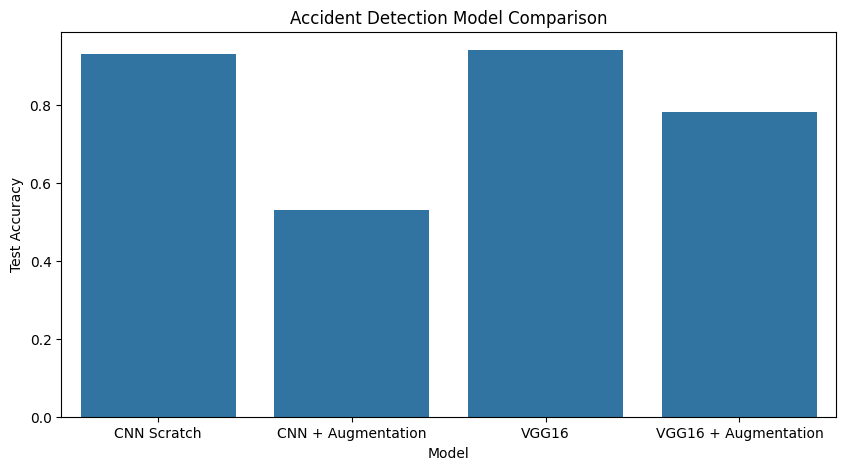

In [125]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

sns.barplot(
    data=results,
    x="Model",
    y="Test Accuracy"
)

plt.title("Accident Detection Model Comparison")

plt.show()

4/4 ━━━━━━━━━━━━━━━━━━━━ 5s 704ms/step
              precision    recall  f1-score   support

           0       1.00      0.87      0.93        47
           1       0.90      1.00      0.95        53

    accuracy                           0.94       100
   macro avg       0.95      0.94      0.94       100
weighted avg       0.95      0.94      0.94       100



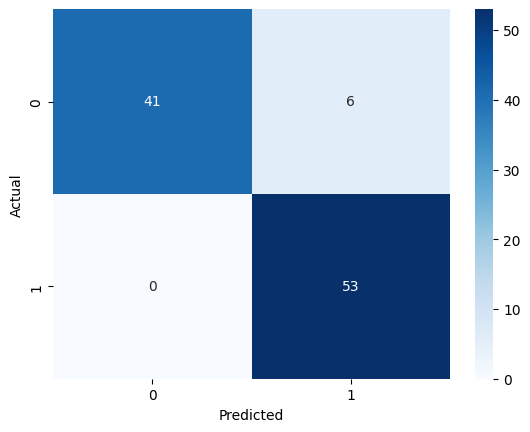

In [126]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import numpy as np

y_pred_prob = model2.predict(test_ds)
y_pred = (y_pred_prob > 0.5).astype(int)

y_true = np.concatenate([y for x, y in test_ds])

print(classification_report(y_true, y_pred))

cm = confusion_matrix(y_true, y_pred)

sns.heatmap(cm,
            annot=True,
            fmt='d',
            cmap='Blues')

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

### Conclusion

A CNN model was developed from scratch and achieved an accuracy of 93%.

A pre-trained VGG16 model achieved the highest test accuracy of 94%.

The confusion matrix showed that VGG16 correctly identified all accident images with 100% recall and only 6 false alarms.

Data augmentation did not improve performance for this dataset and resulted in lower accuracy.

Therefore, the VGG16 transfer learning model was selected as the best model for accident detection due to its highest accuracy, perfect accident detection rate, and strong overall classification performance.